In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
from sklearn.model_selection import train_test_split 
from sklearn.metrics import r2_score,mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer  
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, TargetEncoder
from sklearn.tree import plot_tree


In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LassoCV
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import ElasticNetCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import BaggingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import AdaBoostRegressor
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor
from sklearn.ensemble import VotingRegressor
from sklearn.ensemble import StackingRegressor



In [3]:
car = pd.read_csv("Used_Car_Price_Prediction.csv")
car.sample(10)

,car_name,yr_mfr,fuel_type,kms_run,sale_price,city,times_viewed,body_type,transmission,variant,...,total_owners,broker_quote,original_price,car_rating,ad_created_on,fitness_certificate,emi_starts_from,booking_down_pymnt,reserved,warranty_avail
6235,maruti eeco,2018,petrol & cng,49286,305299,ghaziabad,1451,suv,manual,5 str cng with ac plushtr,...,1,316222,322722.0,great,2021-01-30T09:22:46.252,True,7091,45795,True,False
4422,maruti alto k10,2015,petrol & cng,115447,264099,pune,2175,hatchback,manual,lxi cng,...,1,239000,NaN,good,2021-02-28T06:51:48.903,True,6134,39615,True,False
5834,hyundai i20,2011,petrol,51344,297599,ahmedabad,1864,hatchback,manual,magna o 1.2,...,1,250402,313318.0,good,2021-03-23T12:20:26.571,True,6912,44640,False,False
791,maruti alto 800,2013,petrol,22219,293299,bengaluru,328,hatchback,manual,lxi,...,2,279374,NaN,great,2021-03-20T05:53:48.765,True,6813,43995,False,False
5967,maruti dzire,2019,diesel,24174,725000,ahmedabad,162,sedan,manual,zdi,...,1,548000,NaN,great,2020-06-08T08:05:49.355,True,16840,108750,False,True
2207,honda city,2014,diesel,107208,414399,new delhi,1514,sedan,manual,sv mt diesel,...,1,365700,466494.0,great,2020-10-21T06:13:42.61,True,9625,62160,False,True
4979,hyundai accent,2008,petrol,90511,173399,hyderabad,4503,sedan,manual,gle,...,2,121577,NaN,good,2021-04-18T06:49:23.856,True,4028,26010,True,False
4951,renault kwid,2017,petrol,9415,337299,hyderabad,3468,hatchback,manual,rxt,...,1,293403,NaN,great,2021-04-23T12:12:30.6,True,7835,50595,True,False
1898,hyundai creta,2015,diesel,61207,688999,new delhi,1283,suv,NaN,1.4 s crdi,...,2,677332,NaN,great,2021-03-30T11:51:00.717,True,16004,103350,False,False
6157,hyundai i20,2012,diesel,141069,294499,ghaziabad,711,hatchback,manual,sportz 1.4 crdi,...,1,257941,336019.0,great,2021-02-03T07:56:11.263,True,6840,44175,False,False


In [4]:
car.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7400 entries, 0 to 7399
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   car_name             7400 non-null   object 
 1   yr_mfr               7400 non-null   int64  
 2   fuel_type            7400 non-null   object 
 3   kms_run              7400 non-null   int64  
 4   sale_price           7400 non-null   int64  
 5   city                 7400 non-null   object 
 6   times_viewed         7400 non-null   int64  
 7   body_type            7297 non-null   object 
 8   transmission         6844 non-null   object 
 9   variant              7400 non-null   object 
 10  assured_buy          7400 non-null   bool   
 11  registered_city      7390 non-null   object 
 12  registered_state     7390 non-null   object 
 13  is_hot               7400 non-null   bool   
 14  rto                  7400 non-null   object 
 15  source               7274 non-null   o

In [5]:
car.isnull().sum()

car_name                  0
yr_mfr                    0
fuel_type                 0
kms_run                   0
sale_price                0
city                      0
times_viewed              0
body_type               103
transmission            556
variant                   0
assured_buy               0
registered_city          10
registered_state         10
is_hot                    0
rto                       0
source                  126
make                      0
model                     0
car_availability        620
total_owners              0
broker_quote              0
original_price         3280
car_rating                9
ad_created_on             1
fitness_certificate       8
emi_starts_from           0
booking_down_pymnt        0
reserved                  0
warranty_avail            0
dtype: int64

Dropped_features

In [6]:
car = car.drop(columns=["emi_starts_from", "booking_down_pymnt","broker_quote","rto","variant","ad_created_on","car_name","original_price"])

# columns=["emi_starts_from", "booking_down_pymnt","broker_quote"]
# --> drop this features because we doesnt have this value before sale price decided.

# columns=["rto","variant"]
# --> drop this features because this feature have high number of unique values, and does not add meaningful info to model, due to that we drop this columns. This principle called as Curse of Dimensionality

# columns=["ad_created_on"]
# --> drop this features because this feature contains noise data, time_stamp which logically doesnt help in predicting pattern for sale price of car.       It has zero real-world meaning and prevents the model from generalizing to future cars.

# columns=["car_name"] 
# --> drop this feature because this feature contains text info doesnt add value after encoding

# columns=["original_price"]  
# --> drop this feature because this feature have 44.3% missing data, which doesnt make any sense 

In [7]:
car['model'].value_counts()

model
swift          535
i10            386
swift dzire    377
wagon r 1.0    344
grand i10      275
              ... 
reva             1
verito           1
nuvosport        1
ml class         1
b class          1
Name: count, Length: 185, dtype: int64

In [8]:
car.isnull().sum()

yr_mfr                   0
fuel_type                0
kms_run                  0
sale_price               0
city                     0
times_viewed             0
body_type              103
transmission           556
assured_buy              0
registered_city         10
registered_state        10
is_hot                   0
source                 126
make                     0
model                    0
car_availability       620
total_owners             0
car_rating               9
fitness_certificate      8
reserved                 0
warranty_avail           0
dtype: int64

In [9]:
numerical_cols = car.select_dtypes(include = ["number"]).columns
categorical_cols = car.select_dtypes(include=["object","bool"]).columns
print(numerical_cols.size + categorical_cols.size)

print(f"numerical_cols : {numerical_cols}\n")
print(f"categorical_cols : {categorical_cols}\n")

21
numerical_cols : Index(['yr_mfr', 'kms_run', 'sale_price', 'times_viewed', 'total_owners'], dtype='object')

categorical_cols : Index(['fuel_type', 'city', 'body_type', 'transmission', 'assured_buy',
       'registered_city', 'registered_state', 'is_hot', 'source', 'make',
       'model', 'car_availability', 'car_rating', 'fitness_certificate',
       'reserved', 'warranty_avail'],
      dtype='object')



In [10]:
car[numerical_cols]

,yr_mfr,kms_run,sale_price,times_viewed,total_owners
0,2015,8063,386399,18715,2
1,2016,23104,265499,2676,1
2,2017,23402,477699,609,1
3,2013,39124,307999,6511,1
4,2015,22116,361499,3225,1
...,...,...,...,...,...
7395,2018,53486,604299,2756,1
7396,2018,8854,562599,640,1
7397,2015,46300,400499,795,1
7398,2016,27245,284099,1155,1


In [11]:
car[categorical_cols]

,fuel_type,city,body_type,transmission,assured_buy,registered_city,registered_state,is_hot,source,make,model,car_availability,car_rating,fitness_certificate,reserved,warranty_avail
0,petrol,noida,hatchback,manual,True,delhi,delhi,True,inperson_sale,maruti,swift,in_stock,great,True,False,False
1,petrol,noida,hatchback,manual,True,noida,uttar pradesh,True,inperson_sale,maruti,alto 800,in_stock,great,True,False,False
2,petrol,noida,hatchback,manual,True,agra,uttar pradesh,True,inperson_sale,hyundai,grand i10,in_stock,great,True,False,False
3,diesel,noida,hatchback,manual,True,delhi,delhi,True,inperson_sale,maruti,swift,in_stock,great,True,False,False
4,petrol,noida,hatchback,manual,False,new delhi,delhi,True,inperson_sale,hyundai,grand i10,in_stock,great,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7395,diesel,ghaziabad,sedan,NaN,True,ghaziabad,uttar pradesh,True,inperson_sale,honda,amaze,in_stock,great,True,True,False
7396,petrol,chennai,hatchback,manual,True,chennai,tamil nadu,True,inperson_sale,maruti,ignis,in_stock,great,True,False,False
7397,petrol,pune,sedan,manual,True,pune,maharashtra,True,inperson_sale,honda,amaze,in_stock,great,True,True,False
7398,petrol,new delhi,hatchback,manual,True,delhi,delhi,True,inperson_sale,maruti,alto k10,in_stock,great,True,False,False


Handling missing values with sklearn SimpleImputer

In [12]:
numerical_impute = SimpleImputer(strategy="mean")
car[numerical_cols] = numerical_impute.fit_transform(car[numerical_cols])
categorical_impute = SimpleImputer(strategy="most_frequent")
car[categorical_cols] = categorical_impute.fit_transform(car[categorical_cols])

In [13]:
car.isnull().sum()

yr_mfr                 0
fuel_type              0
kms_run                0
sale_price             0
city                   0
times_viewed           0
body_type              0
transmission           0
assured_buy            0
registered_city        0
registered_state       0
is_hot                 0
source                 0
make                   0
model                  0
car_availability       0
total_owners           0
car_rating             0
fitness_certificate    0
reserved               0
warranty_avail         0
dtype: int64

Encoding with sklearn Onehot encoding, target encoding 

In [14]:
OneHot_cols = ["fuel_type",
    "transmission",
    "body_type",
    "city",
    "registered_state",
    "source",
    "car_availability",
    "car_rating",
    "make",
    "assured_buy",
    "is_hot",
    "fitness_certificate",
    "reserved",
    "warranty_avail"]

onehot_encode = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")

encoded = onehot_encode.fit_transform(car[OneHot_cols])
onehot_encode_cols = onehot_encode.get_feature_names_out(OneHot_cols)
encoded_car = pd.DataFrame(encoded,columns=onehot_encode_cols,index=car.index)
car = pd.concat((car.drop(columns=OneHot_cols), encoded_car), axis=1)




In [15]:
car["model"].nunique()

185

In [16]:

Target_cols = ["registered_city", "model"]

Target_encode = TargetEncoder(
    smooth="auto", 
    cv=5, 
    target_type="continuous", 
    random_state=42
)

encoded_values = Target_encode.fit_transform(car[Target_cols], car["sale_price"])
Target_encode_cols = Target_encode.get_feature_names_out(Target_cols)

encoded_target_car = pd.DataFrame(
    encoded_values, 
    columns=Target_encode_cols, 
    index=car.index
)


car = pd.concat([car.drop(columns=Target_cols), encoded_target_car], axis=1)


In [17]:
car

,yr_mfr,kms_run,sale_price,times_viewed,total_owners,fuel_type_electric,fuel_type_petrol,fuel_type_petrol & cng,fuel_type_petrol & lpg,transmission_manual,...,make_toyota,make_volkswagen,make_volvo,assured_buy_True,is_hot_True,fitness_certificate_True,reserved_True,warranty_avail_True,registered_city,model
0,2015.0,8063.0,386399.0,18715.0,2.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,390840.604654,414349.241785
1,2016.0,23104.0,265499.0,2676.0,1.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,480421.362428,270899.604471
2,2017.0,23402.0,477699.0,609.0,1.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,386660.382758,433253.581577
3,2013.0,39124.0,307999.0,6511.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,386271.672119,413021.345967
4,2015.0,22116.0,361499.0,3225.0,1.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,398025.426147,431974.773132
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7395,2018.0,53486.0,604299.0,2756.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,457079.198373,430021.845847
7396,2018.0,8854.0,562599.0,640.0,1.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,487934.877557,497768.965557
7397,2015.0,46300.0,400499.0,795.0,1.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,435495.788066,430021.845847
7398,2016.0,27245.0,284099.0,1155.0,1.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,377407.693380,276858.963395


 EDA ~ Explolatory Data Analysis 

<Axes: xlabel='model', ylabel='sale_price'>

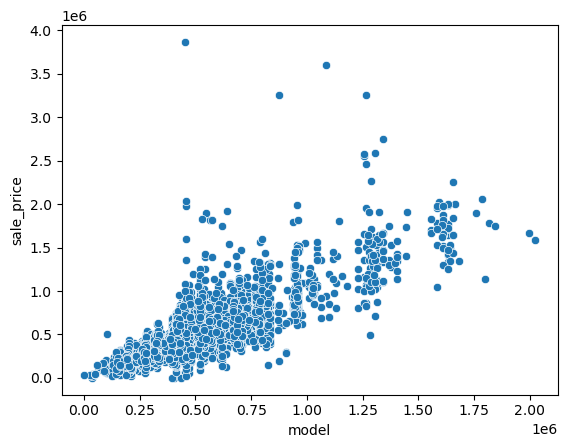

In [18]:
sns.scatterplot(data=car,
                x="model",
                y="sale_price")

<Axes: xlabel='kms_run', ylabel='sale_price'>

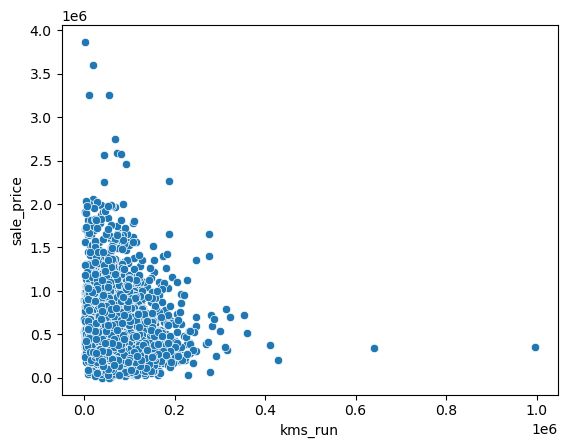

In [19]:
sns.scatterplot(data=car,
                x="kms_run",
                y="sale_price")

In [20]:
X = car.drop(columns=["sale_price"])
y= car["sale_price"]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

# Linear Regression

In [21]:
Linear_Regression = LinearRegression()
Linear_Regression.fit(X_train,y_train)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [22]:
y_train_pred = Linear_Regression.predict(X_train)
y_pred = Linear_Regression.predict(X_test)
print(f"Training Accuracy : {r2_score(y_train,y_train_pred)}")
print(f"Testing Accuracy : {r2_score(y_test,y_pred)}")

Training Accuracy : 0.8330004952452754
Testing Accuracy : 0.8515826100898346


In [23]:
y_test

4698    367499.0
5058    299699.0
7318    404399.0
169     238199.0
1952    397499.0
          ...   
1223    455499.0
210     569899.0
6997    270699.0
6306    250000.0
110     276399.0
Name: sale_price, Length: 1480, dtype: float64

In [24]:
y_pred

array([313922.74084484, 402781.63764266, 452005.98345043, ...,
       208346.28604583, 283795.27349462, 335130.0883766 ], shape=(1480,))

In [25]:
corr = car.corr()

In [26]:
car["model"]

0       414349.241785
1       270899.604471
2       433253.581577
3       413021.345967
4       431974.773132
            ...      
7395    430021.845847
7396    497768.965557
7397    430021.845847
7398    276858.963395
7399    742244.589887
Name: model, Length: 7400, dtype: float64

In [27]:
feature_importance = corr["sale_price"].sort_values(ascending=False)
print(feature_importance)

sale_price              1.000000
model                   0.830526
yr_mfr                  0.518973
body_type_luxury suv    0.362656
body_type_suv           0.356509
                          ...   
total_owners           -0.131306
make_maruti            -0.160760
car_rating_good        -0.202006
transmission_manual    -0.273539
fuel_type_petrol       -0.291880
Name: sale_price, Length: 82, dtype: float64


# LassoCV 

In [28]:
LassoCV_model = LassoCV(max_iter=10000,cv=10)
LassoCV_model.fit(X_train,y_train)

,eps,0.001
,n_alphas,'deprecated'
,alphas,'warn'
,fit_intercept,True
,precompute,'auto'
,max_iter,10000
,tol,0.0001
,copy_X,True
,cv,10
,verbose,False
,n_jobs,None


In [29]:
y_train_pred = LassoCV_model.predict(X_train)
y_pred = LassoCV_model.predict(X_test)
print(f"Training Accuracy : {r2_score(y_train,y_train_pred)}")
print(f"Testing Accuracy : {r2_score(y_test,y_pred)}")

Training Accuracy : 0.7150820260603932
Testing Accuracy : 0.7448321338888967


# RidgeCV

In [30]:
RidgeCV_model = RidgeCV(cv=10)
RidgeCV_model.fit(X_train,y_train)

,alphas,"(0.1, ...)"
,fit_intercept,True
,scoring,None
,cv,10
,gcv_mode,None
,store_cv_results,False
,alpha_per_target,False


In [31]:
y_train_pred = RidgeCV_model.predict(X_train)
y_pred = RidgeCV_model.predict(X_test)
print(f"Training Accuracy : {r2_score(y_train,y_train_pred)}")
print(f"Testing Accuracy : {r2_score(y_test,y_pred)}")

Training Accuracy : 0.8328116960354472
Testing Accuracy : 0.8520767087507386


# ElasticNetCV

In [32]:
ElasticNetCV_model = ElasticNetCV(cv=10, l1_ratio=0.5, max_iter=1000)
ElasticNetCV_model.fit(X_train,y_train)

,l1_ratio,0.5
,eps,0.001
,n_alphas,'deprecated'
,alphas,'warn'
,fit_intercept,True
,precompute,'auto'
,max_iter,1000
,tol,0.0001
,cv,10
,copy_X,True
,verbose,0


In [33]:
y_train_pred = ElasticNetCV_model.predict(X_train)
y_pred = ElasticNetCV_model.predict(X_test)
print(f"Training Accuracy : {r2_score(y_train,y_train_pred)}")
print(f"Testing Accuracy : {r2_score(y_test,y_pred)}")

Training Accuracy : 0.7150186220459629
Testing Accuracy : 0.7448464925153067


# KNeighborsRegressor

In [34]:

KNeighborsRegressor_model = KNeighborsRegressor(n_neighbors=5)
KNeighborsRegressor_model.fit(X_train,y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [35]:
y_train_pred = KNeighborsRegressor_model.predict(X_train)
y_pred = KNeighborsRegressor_model.predict(X_test)
print(f"Training Accuracy : {r2_score(y_train,y_train_pred)}")
print(f"Testing Accuracy : {r2_score(y_test,y_pred)}")

Training Accuracy : 0.8081700940036176
Testing Accuracy : 0.7193619379580496


Hyperparameter tunning using...

# GridSearchCV

In [36]:
k_values = {"n_neighbors": [1,2,3,4,5,6,7,8,9,10,20,21,22,30,31,32,33,34,35,36,37,38,50]}

GridSearchCV_model = GridSearchCV(
    KNeighborsRegressor_model,
    param_grid=k_values,
    cv = 10
)

GridSearchCV_model.fit(X_train, y_train)

,estimator,KNeighborsRegressor()
,param_grid,"{'n_neighbors': [1, 2, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,10
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_neighbors,31


In [37]:

print(f"best K value : {GridSearchCV_model.best_params_} ")
y_train_pred = GridSearchCV_model.predict(X_train)
y_pred = GridSearchCV_model.predict(X_test)
print(f"Training Accuracy : {r2_score(y_train,y_train_pred)}")
print(f"Testing Accuracy : {r2_score(y_test,y_pred)}")


best K value : {'n_neighbors': 31} 
Training Accuracy : 0.7469794365811249
Testing Accuracy : 0.756849366875018


# DecisionTreeRegressor

In [38]:
DecisionTreeRegressor_model = DecisionTreeRegressor()
DecisionTreeRegressor_model.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


Training Accuracy : 1.0
Testing Accuracy : 0.786844006747077


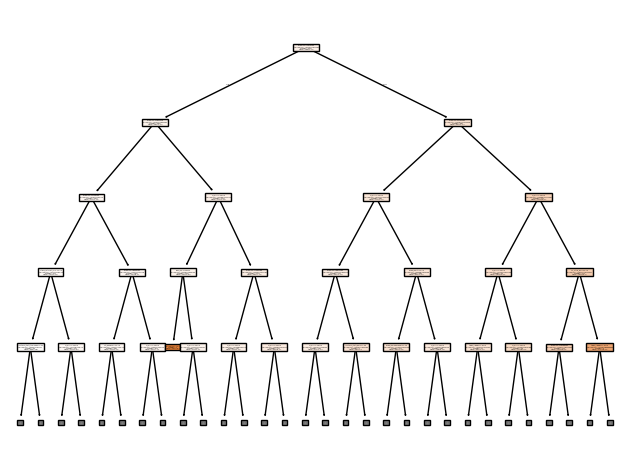

In [39]:
y_train_pred = DecisionTreeRegressor_model.predict(X_train)
y_pred = DecisionTreeRegressor_model.predict(X_test)
print(f"Training Accuracy : {r2_score(y_train,y_train_pred)}")
print(f"Testing Accuracy : {r2_score(y_test,y_pred)}")



plt.Figure(figsize=(18,10))

plot_tree(
    DecisionTreeRegressor_model,
    feature_names=X.columns,
    filled= True,
    max_depth=4

)
plt.tight_layout()

In [40]:
parameters = {"max_depth":[2,3,4,5,6,7,8,9,10], # 10
              "min_samples_leaf":[2,4,6,8,10,20,30,40] # 8
                }

GridSearchCV_model = GridSearchCV(
    DecisionTreeRegressor_model,
    param_grid=parameters,
    cv = 5
    
)



GridSearchCV_model.fit(X_train, y_train)

,estimator,DecisionTreeRegressor()
,param_grid,"{'max_depth': [2, 3, ...], 'min_samples_leaf': [2, 4, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'squared_error'


In [41]:
print(f"best parameters: {GridSearchCV_model.best_params_} ")
y_train_pred = GridSearchCV_model.predict(X_train)
y_pred = GridSearchCV_model.predict(X_test)
print(f"Training Accuracy : {r2_score(y_train,y_train_pred)}")
print(f"Testing Accuracy : {r2_score(y_test,y_pred)}")

best parameters: {'max_depth': 10, 'min_samples_leaf': 8} 
Training Accuracy : 0.8749489825862479
Testing Accuracy : 0.8513443392964313


In [42]:
DecisionTreeRegressor_model = DecisionTreeRegressor(max_depth=10,min_samples_split=20,min_samples_leaf=8,ccp_alpha=0.1)
DecisionTreeRegressor_model.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,10
,min_samples_split,20
,min_samples_leaf,8
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.1


In [43]:

y_train_pred = DecisionTreeRegressor_model.predict(X_train)
y_pred = DecisionTreeRegressor_model.predict(X_test)
print(f"Training Accuracy : {r2_score(y_train,y_train_pred)}")
print(f"Testing Accuracy : {r2_score(y_test,y_pred)}")

Training Accuracy : 0.8679916822250897
Testing Accuracy : 0.8514570571737327


# Support Vector Regresssor 

In [44]:
x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.transform(X_test)

y_train_scaled = y_scaler.fit_transform(y_train.to_numpy().reshape(-1, 1)).ravel()
y_test_scaled = y_scaler.transform(y_test.to_numpy().reshape(-1, 1)).ravel()

SVR_model = SVR()
SVR_model.fit(X_train_scaled, y_train_scaled)

,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,tol,0.001
,C,1.0
,epsilon,0.1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


In [45]:


y_pred_scaled = SVR_model.predict(X_test_scaled)
y_train_pred_scaled = SVR_model.predict(X_train_scaled)
print(f"Training Accuracy : {r2_score(y_train_scaled,y_train_pred_scaled)}")
print(f"Testing Accuracy : {r2_score(y_test_scaled,y_pred_scaled)}")

Training Accuracy : 0.8565056412023294
Testing Accuracy : 0.8511009282598222


In [46]:
# parameters = {
#               "epsilon" : [0,0.001,0.01,0.1,1,2,3,4,5,6]
#             }

# GridSearchCV_model = GridSearchCV(
#     SVR_model,
#     param_grid=parameters,
#     cv = 5
    
# )
# GridSearchCV_model.fit(X_train_scaled, y_train_scaled)

In [47]:
# y_pred_scaled = GridSearchCV_model.predict(X_test_scaled)
# print(f"best parameters: {GridSearchCV_model.best_params_} ")
# print(r2_score(y_test_scaled,y_pred_scaled))

# BaggingRegressor

In [48]:
BaggingRegressor_model = BaggingRegressor(
    estimator= RidgeCV_model,
    n_estimators=101,
    random_state=42,
    oob_score=True
)

BaggingRegressor_model.fit(X_train,y_train)


,estimator,RidgeCV(cv=10)
,n_estimators,101
,max_samples,1.0
,max_features,1.0
,bootstrap,True
,bootstrap_features,False
,oob_score,True
,warm_start,False
,n_jobs,None
,random_state,42
,verbose,0


In [49]:
y_train_pred = BaggingRegressor_model.predict(X_train)
y_pred = BaggingRegressor_model.predict(X_test)
print(f"OBB_score : {BaggingRegressor_model.oob_score_}")
print(f"Training Accuracy : {r2_score(y_train,y_train_pred)}")
print(f"Testing Accuracy : {r2_score(y_test,y_pred)}")

OBB_score : 0.8004238679386655
Training Accuracy : 0.8193847305628637
Testing Accuracy : 0.8505906772584415


# RandomForestRegressor

In [50]:
RandomForestRegressor_model = RandomForestRegressor(n_estimators=101,min_samples_split=20,min_samples_leaf=8,ccp_alpha=0.1)

RandomForestRegressor_model.fit(X_train,y_train)

,n_estimators,101
,criterion,'squared_error'
,max_depth,None
,min_samples_split,20
,min_samples_leaf,8
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [51]:
y_train_pred = RandomForestRegressor_model.predict(X_train)
y_pred = RandomForestRegressor_model.predict(X_test)
print(f"Training Accuracy : {r2_score(y_train,y_train_pred)}")
print(f"Testing Accuracy : {r2_score(y_test,y_pred)}")

Training Accuracy : 0.8867671168180605
Testing Accuracy : 0.8793444333087054


# GradientBoostingRegressor

In [52]:
GradientBoostingRegressor_model = GradientBoostingRegressor(
    learning_rate=0.1, 
    n_estimators=3000)

GradientBoostingRegressor_model.fit(X_train,y_train)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,3000
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [53]:
y_train_pred = GradientBoostingRegressor_model.predict(X_train)
y_pred = GradientBoostingRegressor_model.predict(X_test)
print(f"Training Accuracy : {r2_score(y_train,y_train_pred)}")
print(f"Testing Accuracy : {r2_score(y_test,y_pred)}")

Training Accuracy : 0.9941064117023218
Testing Accuracy : 0.9144441491555232


In [54]:
# estimator_count = {"n_estimators":[10,100,200,300,500,700,1000,1500,2000,3000,5000]} # 3000

# GridSearchCV_model = GridSearchCV(
#     GradientBoostingRegressor_model,
#     param_grid=estimator_count,
#     cv = 5
    
# )
# GridSearchCV_model.fit(X_train, y_train)

In [55]:
# print(f"best parameters: {GridSearchCV_model.best_params_} ")
# y_train_pred = GridSearchCV_model.predict(X_train)
# y_pred = GridSearchCV_model.predict(X_test)
# print(f"Training Accuracy : {r2_score(y_train,y_train_pred)}")
# print(f"Testing Accuracy : {r2_score(y_test,y_pred)}")

# AdaBoostRegressor

In [56]:
AdaBoostRegressor_model = AdaBoostRegressor(n_estimators=1000)
AdaBoostRegressor_model.fit(X_train_scaled,y_train_scaled)


,estimator,None
,n_estimators,1000
,learning_rate,1.0
,loss,'linear'
,random_state,None


In [57]:

y_pred_scaled = AdaBoostRegressor_model.predict(X_test_scaled)
y_train_pred_scaled = AdaBoostRegressor_model.predict(X_train_scaled)
print(f"Training Accuracy : {r2_score(y_train_scaled,y_train_pred_scaled)}")
print(f"Testing Accuracy : {r2_score(y_test_scaled,y_pred_scaled)}")

Training Accuracy : -0.30458970142834874
Testing Accuracy : -0.594318038516759


# XGBRegressor

In [58]:
XGBRegressor_model = xgb.XGBRegressor(
    n_estimators = 1001,
    learning_rate=0.03,       
    max_depth=6,                
    subsample=0.8,            
    colsample_bytree=0.8,       
    reg_alpha=10,               
    reg_lambda=1,              
    random_state=42,
    n_jobs=-1
    )

XGBRegressor_model.fit(X_train,y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [59]:
y_train_pred = XGBRegressor_model.predict(X_train)
y_pred = XGBRegressor_model.predict(X_test)
print(f"Training Accuracy : {r2_score(y_train,y_train_pred)}")
print(f"Testing Accuracy : {r2_score(y_test,y_pred)}")

Training Accuracy : 0.9927214475266551
Testing Accuracy : 0.9244705450993177


# LGBMRegressor

In [60]:
LGBMRegressor_model = lgb.LGBMRegressor(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=6,
    random_state=42,
                     
)

LGBMRegressor_model.fit(X_train,y_train)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003553 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1109
[LightGBM] [Info] Number of data points in the train set: 5920, number of used features: 61
[LightGBM] [Info] Start training from score 458271.504561
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with posit

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,6
,learning_rate,0.03
,n_estimators,1000
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [61]:
y_train_pred = LGBMRegressor_model.predict(X_train)
y_pred = LGBMRegressor_model.predict(X_test)
print(f"Training Accuracy : {r2_score(y_train,y_train_pred)}")
print(f"Testing Accuracy : {r2_score(y_test,y_pred)}")

Training Accuracy : 0.9689766421889865
Testing Accuracy : 0.9054065401220587


# CatBoostRegressor

In [62]:
CatBoostRegressor_model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.03,
    depth=6,
    subsample=0.8,
    l2_leaf_reg=5.0,
    random_seed=42,
    thread_count=-1,
    verbose=100
)

CatBoostRegressor_model.fit(X_train,y_train)

0:	learn: 281354.5733694	total: 152ms	remaining: 2m 32s
100:	learn: 123638.8914292	total: 693ms	remaining: 6.17s
200:	learn: 113016.1104343	total: 1.25s	remaining: 4.96s
300:	learn: 103055.0679779	total: 1.84s	remaining: 4.26s
400:	learn: 92861.1714525	total: 2.46s	remaining: 3.68s
500:	learn: 82995.3667717	total: 3.1s	remaining: 3.08s
600:	learn: 77591.9609907	total: 3.74s	remaining: 2.48s
700:	learn: 72486.2791404	total: 4.45s	remaining: 1.9s
800:	learn: 68287.4972692	total: 5.1s	remaining: 1.27s
900:	learn: 64387.3469773	total: 5.75s	remaining: 632ms
999:	learn: 62725.2091068	total: 6.37s	remaining: 0us


CatBoostRegressor(depth=6, iterations=1000, l2_leaf_reg=5.0, learning_rate=0.03, loss_function='RMSE', random_seed=42, subsample=0.8, verbose=100)

In [63]:
y_train_pred = CatBoostRegressor_model.predict(X_train)
y_pred = CatBoostRegressor_model.predict(X_test)
print(f"Training Accuracy : {r2_score(y_train,y_train_pred)}")
print(f"Testing Accuracy : {r2_score(y_test,y_pred)}")

Training Accuracy : 0.9522670908628694
Testing Accuracy : 0.9102148374086414


# VotingRegressor

In [64]:
VotingRegressor_model = VotingRegressor(
    estimators=[("RandomForestRegressor_model",RandomForestRegressor_model),
                ("LGBMRegressor_model", LGBMRegressor_model),
                ("GradientBoostingRegressor_model",GradientBoostingRegressor_model),
                ("CatBoostRegressor_model",CatBoostRegressor_model),
                ("XGBRegressor_model",XGBRegressor_model)
                ]
)
VotingRegressor_model.fit(X_train,y_train)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001801 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1109
[LightGBM] [Info] Number of data points in the train set: 5920, number of used features: 61
[LightGBM] [Info] Start training from score 458271.504561
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, b

,estimators,"[('RandomForestRegressor_model', ...), ('LGBMRegressor_model', ...), ...]"
,weights,None
,n_jobs,None
,verbose,False
,n_estimators,101
,criterion,'squared_error'
,max_depth,None
,min_samples_split,20
,min_samples_leaf,8
,min_weight_fraction_leaf,0.0
,max_features,1.0


In [65]:
y_train_pred = VotingRegressor_model.predict(X_train)
y_pred = VotingRegressor_model.predict(X_test)
print(f"Training Accuracy : {r2_score(y_train,y_train_pred)}")
print(f"Testing Accuracy : {r2_score(y_test,y_pred)}")

Training Accuracy : 0.9759996326511383
Testing Accuracy : 0.920249500277276


# StackingRegressor

In [66]:
StackingRegressor_model = StackingRegressor(
        estimators=[("RandomForestRegressor_model",RandomForestRegressor_model),
                ("LGBMRegressor_model", LGBMRegressor_model),
                ("GradientBoostingRegressor_model",GradientBoostingRegressor_model),
                ("CatBoostRegressor_model",CatBoostRegressor_model)
                ],
        final_estimator= XGBRegressor_model
)

StackingRegressor_model.fit(X_train,y_train)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000987 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1109
[LightGBM] [Info] Number of data points in the train set: 5920, number of used features: 61
[LightGBM] [Info] Start training from score 458271.504561
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, b

,estimators,"[('RandomForestRegressor_model', ...), ('LGBMRegressor_model', ...), ...]"
,final_estimator,"XGBRegressor(...ree=None, ...)"
,cv,None
,n_jobs,None
,passthrough,False
,verbose,0
,n_estimators,101
,criterion,'squared_error'
,max_depth,None
,min_samples_split,20
,min_samples_leaf,8


In [67]:
y_train_pred = StackingRegressor_model.predict(X_train)
y_pred = StackingRegressor_model.predict(X_test)
print(f"Training Accuracy : {r2_score(y_train,y_train_pred)}")
print(f"Testing Accuracy : {r2_score(y_test,y_pred)}")

Training Accuracy : 0.9434247166913642
Testing Accuracy : 0.8797154168373758


In [68]:
y_train_pred = XGBRegressor_model.predict(X_train)
y_pred = XGBRegressor_model.predict(X_test)
print(f"Training Accuracy : {r2_score(y_train,y_train_pred)}")
print(f"Testing Accuracy : {r2_score(y_test,y_pred)}")

Training Accuracy : 0.9927214475266551
Testing Accuracy : 0.9244705450993177


# Winner ---> XGBRegressor_model

In [69]:
y_test

4698    367499.0
5058    299699.0
7318    404399.0
169     238199.0
1952    397499.0
          ...   
1223    455499.0
210     569899.0
6997    270699.0
6306    250000.0
110     276399.0
Name: sale_price, Length: 1480, dtype: float64

In [70]:
y_pred

array([359694.4 , 286923.7 , 387849.47, ..., 241678.4 , 321082.3 ,
       314792.06], shape=(1480,), dtype=float32)